# 02 · Which known transiting planets give Lazuli the biggest atmospheric signal per transit?

A transmission-spectroscopy program lives or dies by target selection: the feature amplitude scales with the scale height $H$ and $R_p/R_\star^2$, while the noise depends on the host brightness, SED and transit duration. Here we rank the 14 lazuli-exo showcase planets (hot Jupiters to temperate rocky planets) by the template S/N of one Lazuli IFS transit, bracketed by clear and cloudy atmospheres, and check which band carries the signal.

**Instrument / code:** Lazuli IFS, `lazuli_exo.observe` + `.detect()` over all showcase planets and scenarios.

## Prompt to try in Jupyter AI

> Using `lazuli_exo`, loop over every planet in `lazuli_exo.list_planets()` and the scenarios clear, hazy, high_metallicity and cloudy.
> For each, run `lazuli_exo.observe(planet, scenario, n_transits=1, R=100)` and `obs.detect()`; store `template_snr_diagonal`, the per-molecule `band_snr`, and the band with the largest S/N, in a pandas DataFrame.
> Rank the planets by clear-atmosphere template S/N per transit and make a horizontal bar chart (log x-axis) with the cloudy S/N overplotted as a marker, coloured by planet class (hot Jupiter / warm giant / sub-Neptune / temperate) using T_eq and R_p from `lazuli_exo.targets.get_target`.
> Also print the number of transits to reach S/N = 5 in the cloudy case, and the S/N per square-root hour of telescope time assuming an out-of-transit baseline equal to the transit duration.
> Catch and report any UserWarnings (some hosts saturate the detector) and flag those planets in the plot. State what the template S/N does and does not mean.

## Setup

In [1]:
### use pre-cached data, just in case SVO and STScI archive servers are down for sncosmo downloads during experimentation
### for JupyterAI experimentation, feel free to uncomment this -- any newly downloaded data will go to ~/.cache/astropy/sncosmo/ and other places
import os, shutil
MOUNT = os.path.expanduser('~/s3/schmidt-observatory-system')
SRC = f'{MOUNT}/nov26-symposium/sncosmo_data_dir'
DEST = '/home/jovyan/sncosmo_data_dir'

# Copy only if it isn't already there (skip re-copying on every run)
if not os.path.exists(DEST):
    shutil.copytree(SRC, DEST)

# set sncosmo's environment variable for its default data directory
os.environ['SNCOSMO_DATA_DIR'] = DEST

import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
# plt.style.use('gks')

import lazuli_exo
from lazuli_exo.targets import get_target

SCENARIOS = ['clear', 'hazy', 'high_metallicity', 'cloudy']
THUMB = Path('thumbs/02_atmosphere_survey_ranking.png')
print(len(lazuli_exo.list_planets()), 'showcase planets:', ', '.join(lazuli_exo.list_planets()))

14 showcase planets: GJ 1214 b, GJ 3470 b, HAT-P-11 b, HD 189733 b, HD 209458 b, K2-18 b, LHS 1140 b, TOI-270 d, TRAPPIST-1 e, WASP-107 b, WASP-12 b, WASP-121 b, WASP-39 b, WASP-96 b


## Run every planet × scenario (one transit, R = 100)

We also record any warning `observe()` raises: hosts whose noise table still has saturated pixels are flagged as unvalidated.

In [2]:
rows = []
for planet in lazuli_exo.list_planets():
    t = get_target(planet)
    for sc in SCENARIOS:
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter('always')
            o = lazuli_exo.observe(planet, sc, n_transits=1, R=100)
        d = o.detect()
        bands = d['band_snr']
        rows.append(dict(planet=planet, scenario=sc, snr=d['template_snr_diagonal'],
                         best_band=max(bands, key=bands.get), best_band_snr=max(bands.values()),
                         amp_ppm=o.meta['atmosphere']['feature_amplitude_ppm'],
                         T_eq=t['T_eq_K'], R_p_RJ=t['R_p_RJ'], J=t['J_mag'], t14_h=t['t14_s'] / 3600,
                         saturated=any('saturation' in str(x.message) for x in w)))
df = pd.DataFrame(rows)
print(df.groupby('scenario').best_band.value_counts().to_string())

scenario          best_band
clear             H2O          14
cloudy            H2O          14
hazy              H2O          14
high_metallicity  H2O          14


## Rank

Transits to S/N = 5 scale as $(5/\mathrm{S/N}_1)^2$. Because long transits cost more telescope time, we also normalise by $\sqrt{2\,t_{14}}$ (in-transit plus an equal baseline, the same assumption the noise model makes).

In [3]:
def planet_class(r):
    if r.R_p_RJ < 0.25 and r.T_eq < 450: return 'temperate'
    if r.R_p_RJ < 0.45: return 'sub-Neptune / Neptune'
    if r.T_eq < 1000:   return 'warm giant'
    return 'hot Jupiter'

wide = df.pivot(index='planet', columns='scenario', values='snr')
meta = df[df.scenario == 'clear'].set_index('planet')
rank = wide.assign(cls=meta.apply(planet_class, axis=1), best_band=meta.best_band, amp_ppm=meta.amp_ppm.round(0),
                   J=meta.J, saturated=meta.saturated,
                   N5_cloudy=np.ceil((5 / wide.cloudy) ** 2).astype(int),
                   snr_per_sqrt_hr=wide.clear / np.sqrt(2 * meta.t14_h)).sort_values('clear', ascending=False)
rank['rank_per_time'] = rank.snr_per_sqrt_hr.rank(ascending=False).astype(int)
pd.set_option('display.width', 200)
print(rank[['cls', 'J', 'amp_ppm', 'clear', 'hazy', 'high_metallicity', 'cloudy', 'best_band', 'N5_cloudy', 'snr_per_sqrt_hr', 'rank_per_time', 'saturated']].round(2).to_string())

scenario                        cls      J  amp_ppm   clear    hazy  high_metallicity  cloudy best_band  N5_cloudy  snr_per_sqrt_hr  rank_per_time  saturated
planet                                                                                                                                                       
WASP-107 b               warm giant   9.38  10197.0  143.06  124.33             83.46   21.25       H2O          1            61.13              1      False
HD 209458 b             hot Jupiter   6.59   2495.0  111.61  115.08             91.72   20.32       H2O          1            45.03              2      False
HD 189733 b             hot Jupiter   6.07   1717.0   74.23   74.68             56.85    9.05       H2O          1            38.87              3       True
WASP-39 b               hot Jupiter  10.66   7963.0   68.65   71.74             55.19   13.55       H2O          1            28.99              4      False
WASP-121 b              hot Jupiter   9.62   2066.0 

## Hero figure

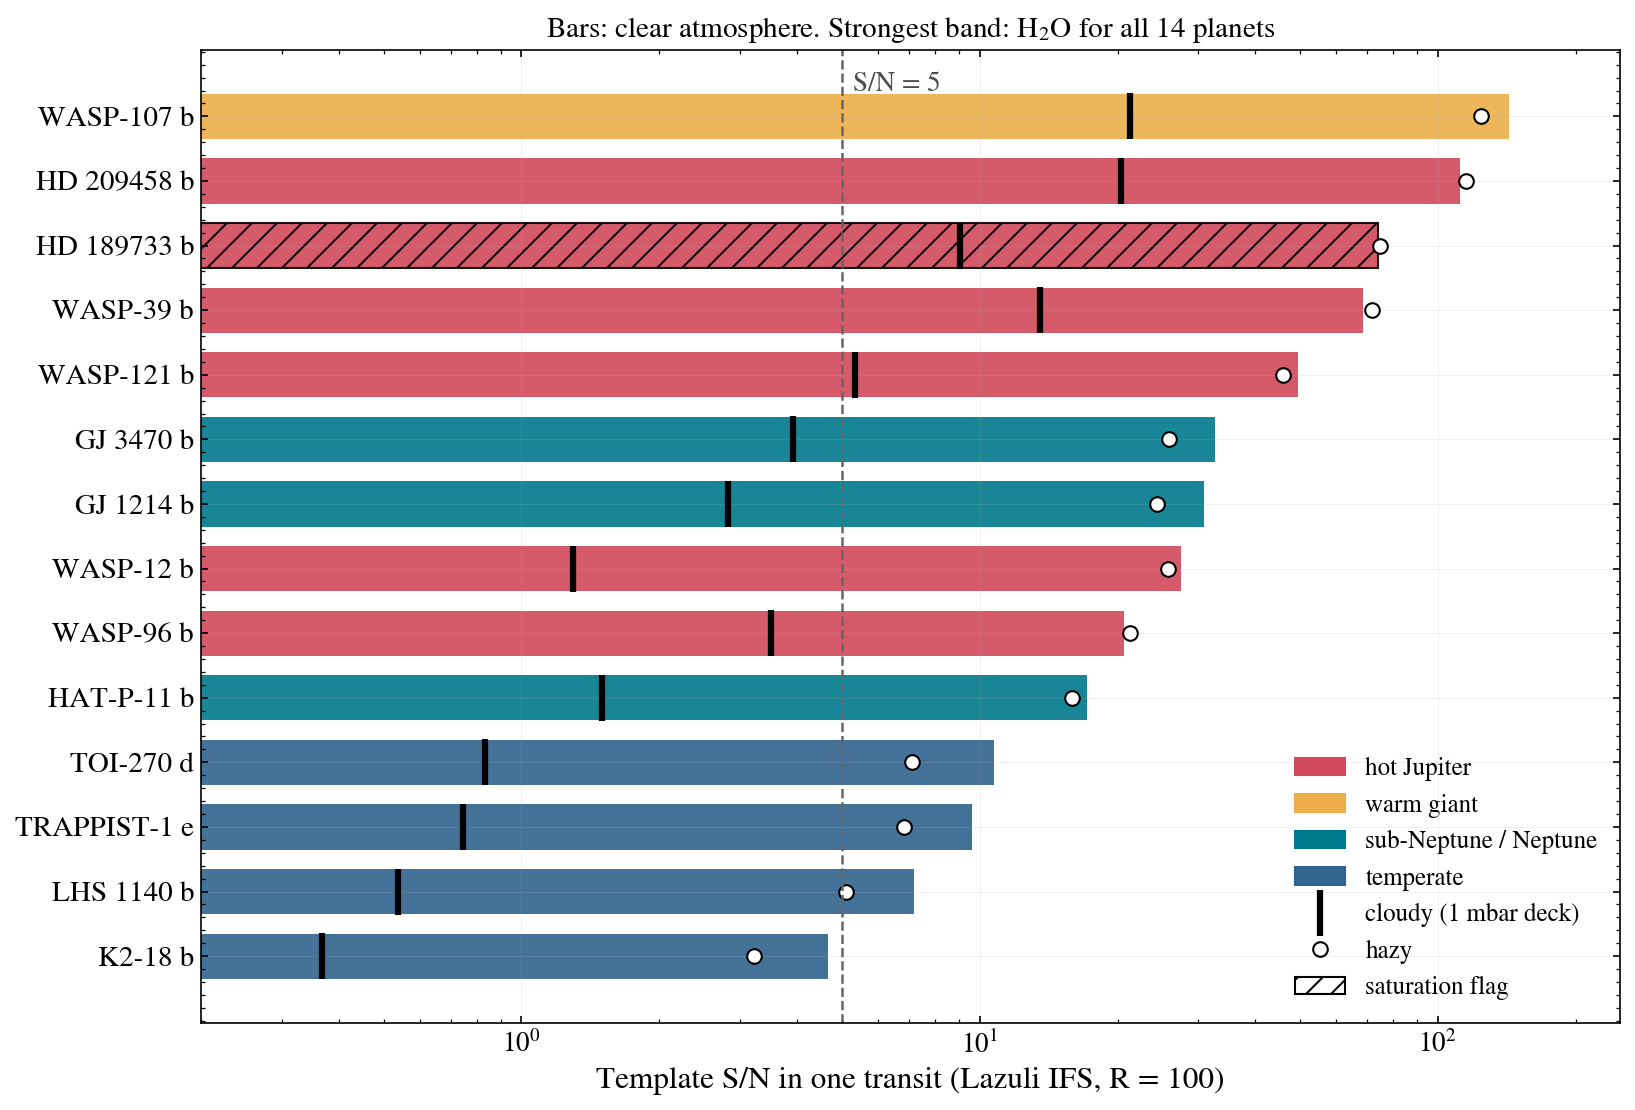

In [4]:
CLS_COLORS = {'hot Jupiter': '#d1495b', 'warm giant': '#edae49', 'sub-Neptune / Neptune': '#00798c', 'temperate': '#30638e'}
r = rank.iloc[::-1]      # best at the top
y = np.arange(len(r))
fig, ax = plt.subplots(figsize=(11, 7.5))
bars = ax.barh(y, r.clear, color=[CLS_COLORS[c] for c in r.cls], height=0.7, alpha=0.9)
for b, sat in zip(bars, r.saturated):
    if sat:
        b.set_hatch('//'); b.set_edgecolor('k')
ax.plot(r.cloudy, y, 'k|', ms=22, mew=3, label='cloudy (1 mbar deck)')
ax.plot(r.hazy, y, 'wo', mec='k', ms=7, label='hazy')
ax.axvline(5, color='0.4', ls='--', lw=1.2)
ax.text(5.3, len(r) - 0.6, 'S/N = 5', color='0.3', fontsize=13)
ax.set_xscale('log'); ax.set_xlim(0.2, 250)
ax.set_yticks(y, r.index, fontsize=14)
ax.set_xlabel('Template S/N in one transit (Lazuli IFS, R = 100)', fontsize=15)
ax.tick_params(axis='x', labelsize=13)
handles = [Patch(color=c, label=k) for k, c in CLS_COLORS.items()]
handles += ax.get_legend_handles_labels()[0] + [Patch(facecolor='w', edgecolor='k', hatch='//', label='saturation flag')]
ax.legend(handles=handles, fontsize=12, loc='lower right')
ax.set_title(f"Bars: clear atmosphere. Strongest band: {'/'.join(sorted(set(rank.best_band))).replace('H2O', 'H$_2$O')} for all {len(rank)} planets", fontsize=14)
fig.tight_layout()
fig.savefig(THUMB, dpi=150)
plt.show()

## Answer

**WASP-107 b** is the best Lazuli transmission target in the set: template S/N = 143 in one clear-atmosphere transit (still 21 with a 1 mbar cloud deck), followed by HD 209458 b (112) and HD 189733 b (74, saturation-flagged). Every planet clears S/N = 5 in one transit if its atmosphere is clear and H$_2$-rich except K2-18 b (4.7), and the H$_2$O band carries the strongest signal for all 14; with clouds, only WASP-107 b, HD 209458 b, WASP-39 b, HD 189733 b and WASP-121 b stay above 5 in a single transit, while the temperate planets need 37–186 transits. Normalising by telescope time (S/N per $\sqrt{\mathrm{hr}}$) moves GJ 1214 b, with its short transit, up from 7th to 5th.

## Caveats & next steps

- **Template S/N is a ranking statistic, not a detection significance**: it is the matched-template amplitude S/N against a flat line with diagonal errors, and the band masks mix every species in the mask (H$_2$O overlaps CH$_4$ near 1.15 µm). CO and NH$_3$ have no band masks in 0.4–1.7 µm, so they never "win".
- **Atmospheres are generic**: one isothermal equilibrium-chemistry model per scenario, no P–T profile, no disequilibrium, no patchy clouds. WASP-12 b and WASP-121 b sit above the validated 2000 K limit; the three temperate planets are clamped to the 300 K chemistry floor.
- **Noise**: photon + read noise only, no systematics floor; HD 189733 b's noise table still has saturated pixels and is unvalidated. Stellar contamination is off (see notebook 03).
- *Extend it:* (1) weight the ranking by schedulability (period, number of transits per year, sky position); (2) add the archive's full transiting-planet list via `simulate()` with presets built from the NASA Exoplanet Archive; (3) compare R = 30, 100, 300 to see whether the ranking depends on binning.